# День 08. Упражнение 04
# Регрессия

## 0. Импорты

In [25]:
import pandas as pd
import numpy as np
from sklearn.model_selection import (
    KFold,
    cross_val_score,
    train_test_split,
    cross_validate,
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Предобработка

1. Прочитай файл [`checker_regression.csv`](https://drive.google.com/file/d/1L8auBzJEghWFewznhhFpcrqxW4GqcfRY/view?usp=sharing).

In [2]:
df = pd.read_csv("../data/checker_regression.csv")
df.head()

,uid,num_commits,pageviews,AVG(diff)
0,user_1,62,28.0,NaN
1,user_1,62,28.0,NaN
2,user_1,62,28.0,NaN
3,user_1,62,28.0,NaN
4,user_1,62,28.0,NaN


2. Заполни пропущенные значения нулями (`0`).

In [4]:
df = df.fillna(0)
df.head()

,uid,num_commits,pageviews,AVG(diff)
0,user_1,62,28.0,0.0
1,user_1,62,28.0,0.0
2,user_1,62,28.0,0.0
3,user_1,62,28.0,0.0
4,user_1,62,28.0,0.0


In [5]:
df.value_counts().head(3)

uid      num_commits  pageviews  AVG(diff)
user_1   62           28.0       0.0          6
user_10  20           89.0       0.0          6
user_17  51           47.0       0.0          6
Name: count, dtype: int64

In [6]:
df = df.drop_duplicates().set_index("uid")
df.info()

<class 'pandas.DataFrame'>
Index: 29 entries, user_1 to user_8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   num_commits  29 non-null     int64  
 1   pageviews    29 non-null     float64
 2   AVG(diff)    29 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 928.0+ bytes


3. Раздели набор данных на обучающую и тестовую выборки с параметрами `test_size=0.2`.

In [7]:
y = df["AVG(diff)"]
X = df.drop(columns=["AVG(diff)"])

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21
)

## 2. Кросс-валидация

1. Напиши функцию `crossval`, которая принимает аргументы: `n_splits` для `KFold()`, `X`, `y`, модель (инициализированный класс с параметрами модели; не забудь о `random_state=21`) и возвращает для данного класса модели результат в таком виде:

```
train - 2696.4496895424836 | test - 1589.9979527104958
train - 2660.957874001452 | test - 2075.102636027137
train - 2847.315529246795 | test - 320.911928168403
train - 2500.7691099659237 | test - 4132.461382030178
train - 2643.927917295123 | test - 2237.8140952197878
train - 2396.295678819444 | test - 4509.650064742476
train - 2003.402267924976 | test - 8403.491474908551
train - 2531.876094212613 | test - 3135.944102735099
train - 2683.1795186023123 | test - 1796.01426292594
train - 2537.1192483996338 | test - 3439.29824116941
Average RMSE on crossval is 3164.0686140637476
```


In [ ]:
def crossval(n_splits, X, y, model):
    """returns average neg_root_mean_squared_error (RMSE)"""
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=21)

    cv_results = cross_validate(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_root_mean_squared_error",
        return_train_score=True,
        n_jobs=-1,
    )

    train_rmse = -cv_results["train_score"]
    test_rmse = -cv_results["test_score"]

    for train, test in zip(train_rmse, test_rmse):
        print(f"train - {train:<18} | test - {test}")

    mean_test_rmse = np.mean(test_rmse)
    print(f"Average RMSE on crossval is {mean_test_rmse}")
    return mean_test_rmse

2. Запусти функцию для моделей `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`. Параметры можешь выбрать самостоятельно, но тщательно убедись, что они подходят.

In [11]:
print("результаты моделей LinearRegression:")
print("-" * 40)
for n_splits in [5, 10, 15]:
    print(f"max_depth={n_splits}")
    crossval(n_splits, X_train, y_train, LinearRegression())
    print("-" * 60)

результаты моделей LinearRegression:
----------------------------------------
max_depth=5


train - 48.9650182985128   | test - 104.57142340670634
train - 67.12604324415598  | test - 61.64346142808743
train - 66.61303918454013  | test - 51.37782993510151
train - 62.66428544831268  | test - 65.76577742150987
train - 64.32380789393129  | test - 60.75794925163608
Average RMSE on crossval is 68.82328828860825
------------------------------------------------------------
max_depth=10
train - 53.33351096491692  | test - 115.2394318363867
train - 62.409919772255556 | test - 69.35808794733022
train - 64.75146423244131  | test - 52.395419621714424
train - 64.04094981627755  | test - 78.18810821407222
train - 63.574089717062186 | test - 58.669554693832154
train - 65.40154560181439  | test - 32.10068854674122
train - 64.40600245557161  | test - 48.59322878192214
train - 61.215472663804725 | test - 82.41734194163652
train - 64.69372263304507  | test - 43.81163345544473
train - 62.80195740062014  | test - 70.47228900535454
Average RMSE on crossval is 65.1245784044435
----------------------

LinearRegression: С ростом числа фолдов средняя ошибка Average RMSE снизилась с 68.82 до 63.95 за счет увеличения объема обучающей выборки на каждом шаге. Оптимальным выбором считаю n_splits=10

In [12]:
print("результаты моделей DecisionTree:")
print("-" * 40)
for depth in [4, 6, 8]:
    print(f"max_depth={depth}")
    model_dt = DecisionTreeRegressor(max_depth=depth, random_state=21)
    crossval(10, X_train, y_train, model_dt)
    print("-" * 60)

результаты моделей DecisionTree:
----------------------------------------
max_depth=4
train - 19.756827933653724 | test - 63.2101257711136
train - 20.876122724299165 | test - 82.25810891019488
train - 22.063461184602122 | test - 11.518137870333035
train - 21.742264634314694 | test - 8.60313250443633
train - 15.222075077495283 | test - 80.25661966467314
train - 21.569529200867827 | test - 15.202795795510772
train - 21.347979223599054 | test - 40.58792924010783
train - 21.569529200867827 | test - 37.190388543278225
train - 20.39538654519797  | test - 30.8121779902038
train - 13.121372766613382 | test - 69.11968786098502
Average RMSE on crossval is 43.87591041508366
------------------------------------------------------------
max_depth=6
train - 0.0                | test - 43.200154320712016
train - 12.965338406690355 | test - 83.15046156973068
train - 0.0                | test - 9.093266739736606
train - 0.0                | test - 8.60313250443633
train - 0.0                | test - 80.

In [ ]:
# DecisionTree: train - 0.0!!  при max_depth=6
# Дерево решений полностью заучило тренировочный датасет.
# Итого лидер: depth=4.

In [ ]:
results = []

print("результаты моделей RandomForest:")
for estimators in range(100, 250, 50):
    for depth in range(5, 20, 5):
        print(f"estimators={estimators}, max_depth={depth}")
        model_rf = RandomForestRegressor(
            n_estimators=estimators, max_depth=depth, random_state=21, n_jobs=-1
        )
        AverageRMSE = crossval(10, X_train, y_train, model_rf)
        results.append(
            {
                "estimators": estimators,
                "max_depth": depth,
                "train_rmse": AverageRMSE,
            }
        )
        print("-" * 60)

результаты моделей RandomForest:
train - 20.63085190341936  | test - 76.83328744586956
train - 23.19186326431637  | test - 81.2838793557124
train - 23.063995847128204 | test - 5.501420331756774
train - 23.72053292111506  | test - 11.17332878618697
train - 24.802698396786475 | test - 69.06849984182773
train - 20.918185796239708 | test - 39.78281186700455
train - 21.64642166645181  | test - 55.97960571048663
train - 23.319924381128516 | test - 24.10209705184025
train - 20.853088203556823 | test - 26.21383867001997
train - 17.113184803676937 | test - 69.6015772708772
Average RMSE on crossval is 45.9540346331582
------------------------------------------------------------
train - 19.85306588532919  | test - 76.53685427174808
train - 22.671373358544045 | test - 81.61793883314117
train - 21.694829255044976 | test - 5.71235319286195
train - 22.7272784086383   | test - 9.177142450433896
train - 24.38477655695876  | test - 70.14702143355767
train - 19.90791216218836  | test - 40.07320878716852


In [ ]:
for model_characteristics in results:
    print(f"model: {model_characteristics}")

model: {'estimators': 100, 'max_depth': 5, 'train_rmse': np.float64(45.9540346331582)}
model: {'estimators': 100, 'max_depth': 10, 'train_rmse': np.float64(45.759900048221446)}
model: {'estimators': 100, 'max_depth': 15, 'train_rmse': np.float64(45.759900048221446)}
model: {'estimators': 150, 'max_depth': 5, 'train_rmse': np.float64(46.28030868394969)}
model: {'estimators': 150, 'max_depth': 10, 'train_rmse': np.float64(46.150702241205146)}
model: {'estimators': 150, 'max_depth': 15, 'train_rmse': np.float64(46.15070224120514)}
model: {'estimators': 200, 'max_depth': 5, 'train_rmse': np.float64(45.51710915111661)}
model: {'estimators': 200, 'max_depth': 10, 'train_rmse': np.float64(45.38257040437203)}
model: {'estimators': 200, 'max_depth': 15, 'train_rmse': np.float64(45.38257040437203)}


Лучший результат у модели RandomForest с пар-ми: estimators=200, max_depth=10 с ошибкой 45.3825.

## 3. Предсказания и оценка

1. Сделай предсказания на тестовом наборе данных для каждой из трёх моделей с финальными параметрами.
2. Построй график для каждой модели, где по оси x — фактическая средняя разница, а по оси y — предсказание модели.
3. Как должен выглядеть график в идеальном случае? Напиши ответ в markdown-ячейке в конце раздела.

In [ ]:
final_lr = LinearRegression(fit_intercept=False)
final_dt = DecisionTreeRegressor(max_depth=4, random_state=21)
final_rf = RandomForestRegressor(
    n_estimators=200, max_depth=10, random_state=21, n_jobs=-1
)

In [19]:
final_lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",False
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [20]:
final_dt.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",21
,"max_leaf

In [21]:
final_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

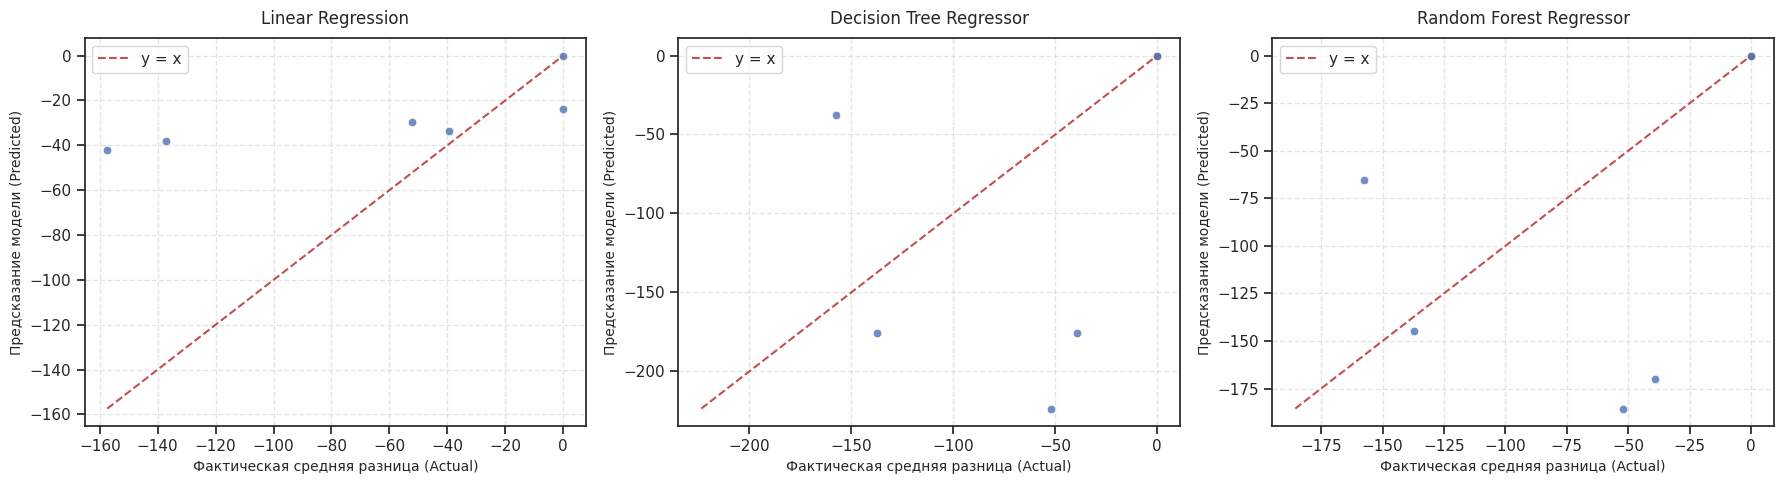

In [ ]:
regression_models = [
    ("Linear Regression", final_lr),
    ("Decision Tree Regressor", final_dt),
    ("Random Forest Regressor", final_rf),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, regression_models):
    y_pred_test = model.predict(X_test)

    sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.8, ax=ax)

    min_val = min(y_test.min(), y_pred_test.min())
    max_val = max(y_test.max(), y_pred_test.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="r",
        linestyle="--",
        label="y = x",
    )

    ax.set_title(name, fontsize=12, pad=10)
    ax.set_xlabel("Фактическая средняя разница (Actual)", fontsize=10)
    ax.set_ylabel("Предсказание модели (Predicted)", fontsize=10)
    ax.grid(True, axis="both", linestyle="--", alpha=0.5)
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()